# Trabajo Práctico — Decision Tree vs Random Forest

**Inteligencia Artificial para Datos** · UTN F.R.Re. · Ciclo lectivo 2026

**Dataset:** `data_cardiovascular_risk.csv` — Framingham Heart Study, riesgo de
enfermedad coronaria a 10 años (`TenYearCHD`).

Este notebook es el entregable ejecutable: hace el pre-procesamiento, entrena
las implementaciones **propias** de Decision Tree (C4.5) y Random Forest,
compara su rendimiento bajo distintas parametrizaciones y expone una interfaz
para correr pruebas fácilmente.

### Contenido

0. [Entorno](#0) · 1. [Carga](#1) · 2. [Auditoría inicial](#2) ·
3. [Pre-procesamiento](#3) · 4. [Decision Tree](#4) · 5. [Random Forest](#5)
6. [Validación vs. scikit-learn](#6) · 7. [Protocolo](#7) ·
8. [Barridos DT](#8) · 9. [Barridos RF](#9) · 10. [Ablaciones](#10) ·
11. [Comparación final](#11) · 12. [Interfaz](#12) · 13. [Conclusiones](#13)

> **Cómo ejecutarlo en Colab:** abrirlo desde GitHub con el badge o subir
> solamente este notebook. La primera celda descarga automáticamente los
> cuatro módulos y el CSV desde el repositorio, y sólo si faltan. La subida
> manual queda como respaldo si no hay acceso a la red.

<a id="0"></a>
## 0. Entorno y dependencias

Todo corre en **Google Colab** sin instalaciones extra (numpy, pandas,
matplotlib, scikit-learn e ipywidgets vienen preinstalados). Los algoritmos
DT y RF están implementados desde cero en `dt_rf.py`; scikit-learn se usa
para métricas y validación. Los imputadores iterativo y KNN también son
propios del proyecto.

La celda siguiente es un *bootstrap* idempotente: revisa si `dt_rf.py`,
`preprocessing.py`, `experiments.py`, `plots.py` y
`data_cardiovascular_risk.csv` están en el directorio de trabajo y descarga
de GitHub los que falten. Si los archivos ya están en el directorio de trabajo, no descarga nada.
La subida manual se usa únicamente como respaldo.


In [1]:
# Bootstrap idempotente: traer los archivos que falten desde el repositorio.
# Si el notebook se abrió desde GitHub (Colab clona el repo) o los archivos ya
# están en /content, esta celda no descarga nada.
import os
import urllib.request

# Versión congelada para que el notebook sea reproducible. Actualizar este
# hash si se modifican los módulos .py o el CSV en el repositorio.
COMMIT = "e9f1190b35a135ba8f67037acab68b9b08bf844e"
BASE = (f"https://raw.githubusercontent.com/kahnaisehC/"
        f"analisis-riesgo-cardiovascular/{COMMIT}")
ARCHIVOS = [
    "dt_rf.py",
    "preprocessing.py",
    "experiments.py",
    "plots.py",
    "data_cardiovascular_risk.csv",
]

for nombre in ARCHIVOS:
    if os.path.exists(nombre):
        continue
    try:
        urllib.request.urlretrieve(f"{BASE}/{nombre}", nombre)
        print(f"↓ Descargado desde GitHub: {nombre}")
    except Exception as exc:
        if os.path.exists(nombre):
            os.remove(nombre)
        print(f"⚠ No se pudo descargar {nombre}: {exc}")

print("Listos:", [a for a in ARCHIVOS if os.path.exists(a)])

Listos: ['dt_rf.py', 'preprocessing.py', 'experiments.py', 'plots.py', 'data_cardiovascular_risk.csv']


In [2]:
import json
import os
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

# --- ¿Estamos en Colab? ----------------------------------------------------
try:
    import google.colab  # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

# --- Asegurar que los módulos del TP estén disponibles ---------------------
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

try:
    import dt_rf, preprocessing, experiments, plots
except ModuleNotFoundError:
    if EN_COLAB:
        from google.colab import files
        print("No se pudieron descargar los módulos del TP (¿sin red?). "
              "Subí manualmente dt_rf.py, preprocessing.py, experiments.py "
              "y plots.py:")
        files.upload()
    import dt_rf, preprocessing, experiments, plots

from dt_rf import DecisionTree, RandomForest
import experiments as E
from plots import draw_tree, plot_confusion_matrix, plot_roc_pr, plot_curve, plot_importances

from IPython.display import display, Markdown

SEED = 42
N_SPLITS = 5
RUTA_DATOS = "data_cardiovascular_risk.csv"
RUTA_PROCESADO = "data/dataset_procesado.csv"
os.makedirs("data", exist_ok=True)
os.makedirs("results", exist_ok=True)

print("Colab:", EN_COLAB)
print("Versiones:", np.__version__, pd.__version__)

Colab: False
Versiones: 2.5.4 3.1.0


<a id="1"></a>
## 1. Carga del dataset

El dataset tiene 3.390 registros de pacientes, 15 atributos clínicos + un
identificador, y la variable objetivo `TenYearCHD` (1 = desarrolló enfermedad
coronaria en 10 años).

In [3]:
if not os.path.exists(RUTA_DATOS):
    if EN_COLAB:
        from google.colab import files
        print("No se pudo descargar el CSV (¿sin red?). "
              "Subí manualmente data_cardiovascular_risk.csv:")
        subidos = files.upload()
        RUTA_DATOS = list(subidos)[0]
    else:
        raise FileNotFoundError(
            f"No se encontró {RUTA_DATOS}. Copiá el CSV al directorio de trabajo."
        )

df_raw = preprocessing.load_raw(RUTA_DATOS)
print(f"Dataset: {df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas")
display(df_raw.head())

Dataset: 3,390 filas x 17 columnas


,id,age,education,sex,is_smoking,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,0,64,2.0000,F,YES,3.0000,0.0000,0,0,0,221.0000,148.0000,85.0000,NaN,90.0000,80.0000,1
1,1,36,4.0000,M,NO,0.0000,0.0000,0,1,0,212.0000,168.0000,98.0000,29.7700,72.0000,75.0000,0
2,2,46,1.0000,F,YES,10.0000,0.0000,0,0,0,250.0000,116.0000,71.0000,20.3500,88.0000,94.0000,0
3,3,50,1.0000,M,YES,20.0000,0.0000,0,1,0,233.0000,158.0000,88.0000,28.2600,68.0000,94.0000,1
4,4,64,1.0000,F,YES,30.0000,0.0000,0,0,0,241.0000,136.5000,85.0000,26.4200,70.0000,77.0000,0


<a id="2"></a>
## 2. Auditoría inicial del dataset

Antes de tocar nada: nulos, duplicados, outliers, tipos y anomalías lógicas.
Esta salida es la que se transcribe en la sección **"Informe inicial"** del
informe.

In [4]:
info = preprocessing.audit(df_raw)
display(Markdown(preprocessing.audit_to_markdown(info)))

# Auditoría inicial del dataset

- Registros: **3390**
- Columnas: **17**
- Celdas nulas: **510** (0.88 % del total)
- Filas con al menos un nulo: **463** (13.66 %)
- Duplicados exactos: **0** (sin `id`: 0)

## Valores faltantes por columna

| Columna | Tipo | Nulos | % | Únicos |
|---|---|---:|---:|---:|
| `glucose` | float64 | 304 | 8.97 | 132 |
| `education` | float64 | 87 | 2.57 | 4 |
| `BPMeds` | float64 | 44 | 1.30 | 2 |
| `totChol` | float64 | 38 | 1.12 | 240 |
| `cigsPerDay` | float64 | 22 | 0.65 | 32 |
| `BMI` | float64 | 14 | 0.41 | 1259 |
| `heartRate` | float64 | 1 | 0.03 | 68 |
| `id` | int64 | 0 | 0.00 | 3390 |
| `age` | int64 | 0 | 0.00 | 39 |
| `prevalentHyp` | int64 | 0 | 0.00 | 2 |
| `prevalentStroke` | int64 | 0 | 0.00 | 2 |
| `sex` | str | 0 | 0.00 | 2 |
| `is_smoking` | str | 0 | 0.00 | 2 |
| `diaBP` | float64 | 0 | 0.00 | 142 |
| `sysBP` | float64 | 0 | 0.00 | 226 |
| `diabetes` | int64 | 0 | 0.00 | 2 |
| `TenYearCHD` | int64 | 0 | 0.00 | 2 |

## Balance de clase

`TenYearCHD`: 0 = 2879 (84.93 %), 1 = 511 (15.07 %). Ratio mayoritaria:minoritaria = **5.63:1**.

## Outliers

| Columna | IQR (n) | IQR (%) | z > 3 (n) | z > 3 (%) | Límite inf | Límite sup |
|---|---:|---:|---:|---:|---:|---:|
| `age` | 0 | 0.0 | 0 | 0.0 | 21.0 | 77.0 |
| `cigsPerDay` | 9 | 0.27 | 17 | 0.5 | -30.0 | 50.0 |
| `totChol` | 43 | 1.28 | 19 | 0.57 | 119.0 | 351.0 |
| `sysBP` | 105 | 3.1 | 39 | 1.15 | 76.5 | 184.5 |
| `diaBP` | 58 | 1.71 | 36 | 1.06 | 51.25 | 113.25 |
| `BMI` | 77 | 2.28 | 46 | 1.36 | 15.49 | 35.57 |
| `heartRate` | 64 | 1.89 | 19 | 0.56 | 45.5 | 105.5 |
| `glucose` | 158 | 5.12 | 42 | 1.36 | 47.0 | 111.0 |

## Inconsistencias detectadas

- cigs>0 con is_smoking=NO: **0**
- cigs=0 con is_smoking=YES: **0**
- BPMeds nulo con prevalentHyp=0: **25**
- BPMeds nulo con prevalentHyp=1: **19**
- diaBP >= sysBP: **0**

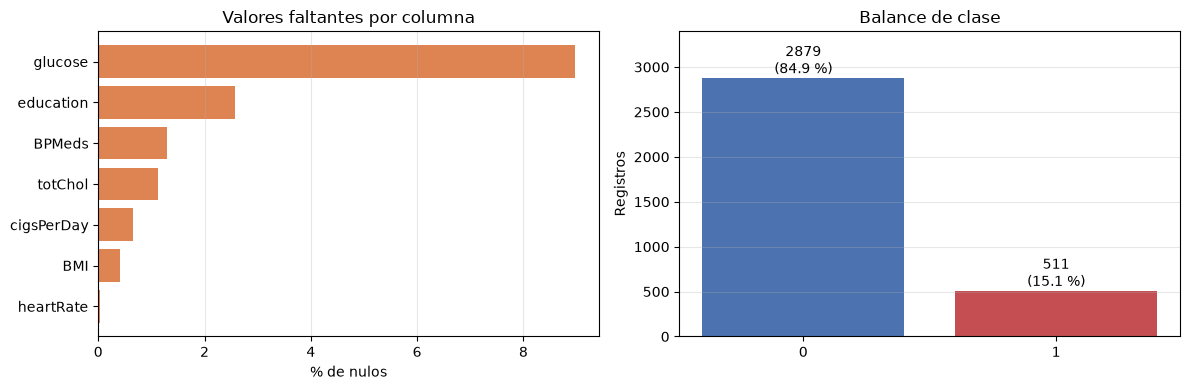

In [5]:
# Visualización de nulos y balance de clase
faltantes = info["missing"]["pct"]
faltantes = faltantes[faltantes > 0].to_dict()

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
plots.plot_missing(faltantes, ax=axs[0])
plots.plot_target_balance(df_raw["TenYearCHD"].to_numpy(), ax=axs[1])
plt.tight_layout()
plt.show()

In [6]:
# Distribución de las variables continuas (para ver colas y outliers)
continuas = ["age", "cigsPerDay", "totChol", "sysBP", "diaBP", "BMI", "heartRate", "glucose"]
df_raw[continuas].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,"3,390.0000",49.5400,8.5900,32.0000,42.0000,49.0000,56.0000,70.0000
cigsPerDay,"3,368.0000",9.0700,11.8800,0.0000,0.0000,0.0000,20.0000,70.0000
totChol,"3,352.0000",237.0700,45.2500,107.0000,206.0000,234.0000,264.0000,696.0000
sysBP,"3,390.0000",132.6000,22.2900,83.5000,117.0000,128.5000,144.0000,295.0000
diaBP,"3,390.0000",82.8800,12.0200,48.0000,74.5000,82.0000,90.0000,142.5000
BMI,"3,376.0000",25.7900,4.1200,15.9600,23.0200,25.3800,28.0400,56.8000
heartRate,"3,389.0000",75.9800,11.9700,45.0000,68.0000,75.0000,83.0000,143.0000
glucose,"3,086.0000",82.0900,24.2400,40.0000,71.0000,78.0000,87.0000,394.0000


<a id="3"></a>
## 3. Pre-procesamiento

Decisiones (todas quedan registradas con su conteo en el informe final):

| Paso | Decisión | Motivo |
|---|---|---|
| `id` | se elimina | identificador, sin poder predictivo |
| Duplicados | 0 detectados | se verifica y se reporta |
| Nulos | **imputar**, no borrar filas | borrar las 463 filas con algún nulo eliminaría 67 positivos de una clase que ya es 15 % |
| `BPMeds` | regla: 0 si `prevalentHyp = 0` | el nulo es estructural (no toma medicación) |
| Continuas | MICE-style iterativo propio | preserva correlaciones entre presión, colesterol, glucosa y BMI |
| Outliers | **winsorizar p1–p99** | muchos son valores clínicos reales (glucosa 394, sysBP 295) que pertenecen a la clase de riesgo |
| `age`, `cigsPerDay` | **no** se recortan | sus colas son informativas: mayores y fumadores empedernidos son la población de riesgo |
| `is_smoking` | se conserva (se prueba quitarla en la ablación) | es redundante con `cigsPerDay` |
| Nuevo atributo | `pulsePressure = sysBP - diaBP` | proxy de rigidez arterial, muy usado en riesgo cardiovascular |

In [7]:
prep = preprocessing.Preprocessor(
    imputer="mice",
    clip_outliers=True,
    clip_lower=0.01,
    clip_upper=0.99,
    drop_is_smoking=False,
    add_pulse_pressure=True,
)
df = prep.fit_transform(df_raw)
df.to_csv(RUTA_PROCESADO, index=False)

display(Markdown(prep.report_markdown()))
print(f"\nDataset procesado guardado en {RUTA_PROCESADO}: {df.shape}")
display(df.head())

# Informe del pre-procesamiento

- Filas de entrada: **3390**
- Filas eliminadas: **0** (target nulo: 0)
- Filas de salida: **3390**
- Columnas eliminadas: **id**
- Columnas de salida: **17**
- Nulos en la salida: **0**

## Valores imputados

| Columna | Valores imputados |
|---|---:|
| `education` | 87 |
| `BPMeds (regla prevalentHyp=0)` | 25 |
| `cigsPerDay` | 22 |
| `totChol` | 38 |
| `BMI` | 14 |
| `heartRate` | 1 |
| `glucose` | 304 |
| `BPMeds` | 19 |

## Outliers winsorizados (p1-p99)

| Columna | Valores recortados |
|---|---:|
| `totChol` | 67 |
| `sysBP` | 68 |
| `diaBP` | 66 |
| `BMI` | 68 |
| `heartRate` | 53 |
| `glucose` | 53 |

Total de celdas imputadas: **510**
Total de celdas winsorizadas: **375**


Dataset procesado guardado en data/dataset_procesado.csv: (3390, 17)


,age,education,sex,is_smoking,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,pulsePressure,TenYearCHD
0,64.0000,2,1,1,3.0000,0,0,0,0,221.0000,148.0000,85.0000,26.3248,90.0000,80.0000,63.0000,1
1,36.0000,4,0,0,0.0000,0,0,1,0,212.0000,168.0000,98.0000,29.7700,72.0000,75.0000,70.0000,0
2,46.0000,1,1,1,10.0000,0,0,0,0,250.0000,116.0000,71.0000,20.3500,88.0000,94.0000,45.0000,0
3,50.0000,1,0,1,20.0000,0,0,1,0,233.0000,158.0000,88.0000,28.2600,68.0000,94.0000,70.0000,1
4,64.0000,1,1,1,30.0000,0,0,0,0,241.0000,136.5000,85.0000,26.4200,70.0000,77.0000,51.5000,0


In [8]:
# Controles de calidad sobre el dataset limpio
assert df.isna().sum().sum() == 0, "quedaron nulos"
assert df["TenYearCHD"].isin([0, 1]).all()
assert "id" not in df.columns, "el id debería haberse eliminado"
print("Sin nulos. Clases:", dict(df["TenYearCHD"].value_counts()))
print("Columnas:", list(df.columns))

# El dataset completo procesado se guarda como entregable. Para evaluar, en
# cambio, se divide el dataset RAW y el preprocesador se ajusta sólo en train.
from sklearn.model_selection import train_test_split
raw_idx = np.arange(len(df_raw))
y_raw = df_raw["TenYearCHD"].to_numpy()
idx_tr, idx_te = train_test_split(
    raw_idx, test_size=0.30, random_state=SEED, stratify=y_raw
)
prep_holdout = preprocessing.Preprocessor(
    imputer="mice", clip_outliers=True, add_pulse_pressure=True
)
clean_tr = prep_holdout.fit_transform(df_raw.iloc[idx_tr].reset_index(drop=True))
clean_te = prep_holdout.transform(df_raw.iloc[idx_te].reset_index(drop=True))
X_tr = clean_tr.drop(columns=["TenYearCHD"])
y_tr = clean_tr["TenYearCHD"].to_numpy()
X_te = clean_te.drop(columns=["TenYearCHD"])
y_te = clean_te["TenYearCHD"].to_numpy()

# X/y completos sólo se usan para reentrenar un modelo descriptivo sobre todo
# el dataset. Los barridos y las métricas usan cross_validate_with_preprocessing.
X = df.drop(columns=["TenYearCHD"])
y = df["TenYearCHD"].to_numpy()
PREP_FACTORY = lambda: preprocessing.Preprocessor()
print(f"Train: {X_tr.shape}  Test: {X_te.shape}")

Sin nulos. Clases: {np.int64(0): np.int64(2879), np.int64(1): np.int64(511)}
Columnas: ['age', 'education', 'sex', 'is_smoking', 'cigsPerDay', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose', 'pulsePressure', 'TenYearCHD']
Train: (2373, 16)  Test: (1017, 16)


<a id="4"></a>
## 4. Decision Tree (C4.5) — implementación propia

`DecisionTree` (en `dt_rf.py`) implementa:

- **Criterios**: entropía con *gain ratio* (C4.5) o Gini.
- **Splits numéricos**: umbral `≤` elegido por barrido ordenado O(n log n).
- **Splits categóricos**: multi-vía, una rama por categoría.
- **Parada**: `max_depth`, `min_samples_split`, `min_samples_leaf`,
  `min_impurity_decrease`.
- **Poda**: pesimista de C4.5 y *Reduced Error Pruning* con validación.
- **Desbalance**: `class_weight="balanced"`.
- **Importancia de atributos**: decremento ponderado de impureza.

Los atributos categóricos se detectan automáticamente desde los dtypes del
DataFrame (`education`, `sex`, `is_smoking`, `BPMeds`, `prevalent*`, `diabetes`).

In [9]:
arbol = DecisionTree(
    criterion="gini",       # entropía + gain ratio también disponible
    max_depth=4,
    min_samples_leaf=20,
    class_weight=None,
    random_state=SEED,
)
t0 = time.perf_counter()
arbol.fit(X_tr, y_tr)
print(f"Entrenado en {time.perf_counter() - t0:.3f} s")
print(f"Hojas: {arbol.get_n_leaves()}  |  Profundidad: {arbol.get_depth()}")

proba_arbol = arbol.predict_proba(X_te)[:, 1]
res_arbol = E.evaluate_with_train_threshold(
    y_tr, arbol.predict_proba(X_tr)[:, 1], y_te, proba_arbol,
    pred_test=arbol.predict(X_te),
)
pd.Series(res_arbol).round(4).to_frame("valor")

Entrenado en 0.033 s
Hojas: 13  |  Profundidad: 4


,valor
accuracy,0.8456
balanced_accuracy,0.5084
precision,0.3333
recall,0.0261
f1,0.0485
roc_auc,0.6875
pr_auc,0.2735
threshold_opt,0.1917
f1_opt,0.3245


In [10]:
print(arbol.export_text(list(X.columns)))

si sysBP <= 144.8:
  si age <= 46.5:
    si cigsPerDay <= 9.5:
      si diaBP <= 82.25:
        => clase=0  (n=301, p=0.983)
      sino:
        => clase=0  (n=156, p=0.929)
    sino:
      si totChol <= 246.5:
        => clase=0  (n=295, p=0.932)
      sino:
        => clase=0  (n=120, p=0.808)
  sino:
    si age <= 65.5:
      si glucose <= 117.5:
        => clase=0  (n=855, p=0.858)
      sino:
        => clase=0  (n=24, p=0.667)
    sino:
      => clase=0  (n=27, p=0.556)
sino:
  si sysBP <= 192.2:
    si age <= 48.5:
      si education == np.float64(1.0):
        => clase=0  (n=83, p=0.867)
      si education == np.float64(2.0):
        => clase=0  (n=46, p=0.913)
    sino:
      si sex == np.float64(0.0):
        => clase=0  (n=153, p=0.608)
      si sex == np.float64(1.0):
        => clase=0  (n=267, p=0.783)
  sino:
    si heartRate <= 78:
      => clase=1  (n=21, p=0.714)
    sino:
      => clase=0  (n=25, p=0.600)


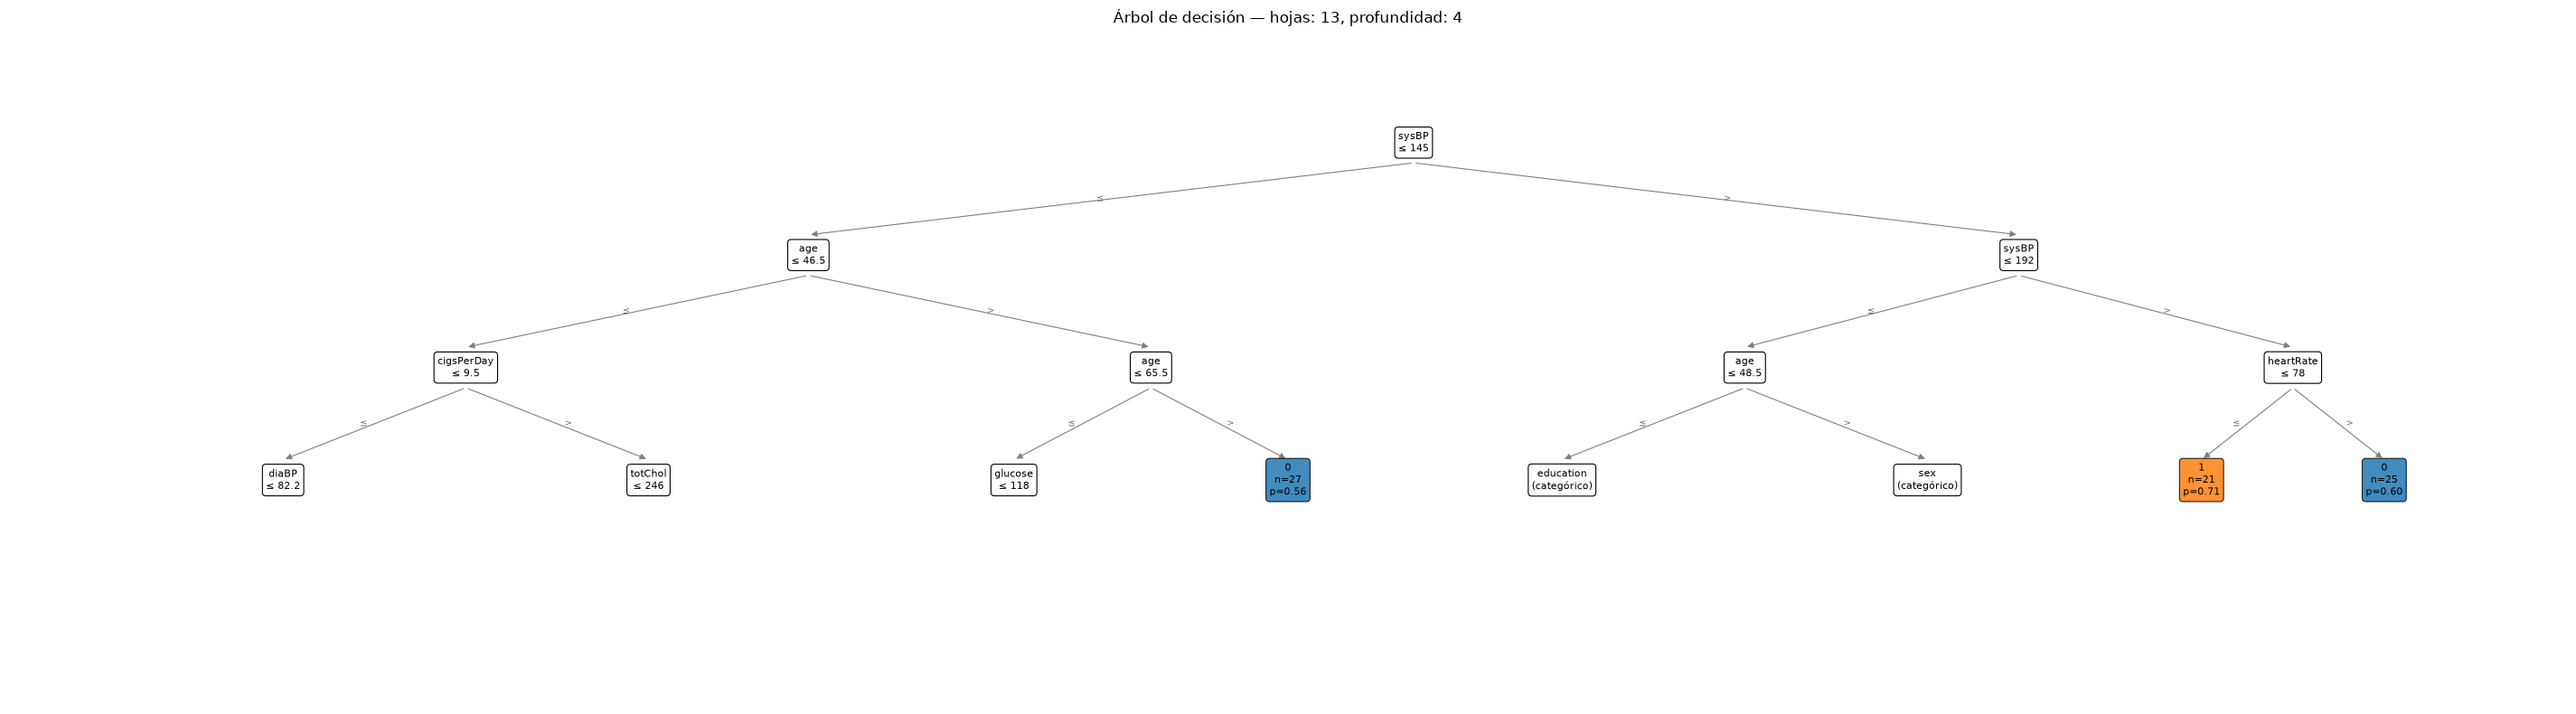

In [11]:
# Dibujo del árbol (las primeras 3 capas)
draw_tree(arbol, list(X.columns), max_depth=3)
plt.show()

<a id="5"></a>
## 5. Random Forest — implementación propia

`RandomForest` combina:

- **Bagging**: cada árbol entrena con una muestra bootstrap.
- **Subespacios aleatorios**: en cada split se evalúa sólo un subconjunto de
  atributos (`max_features="sqrt"` por defecto, el valor clásico de Breiman).
- **Voto**: suave (promedio de probabilidades) o duro (mayoría).
- **OOB**: exactitud *out-of-bag*, estimación gratuita del error de
  generalización (cada muestra se predice con los árboles que no la vieron).

In [12]:
bosque = RandomForest(
    n_estimators=100,
    criterion="gini",
    max_depth=8,
    max_features="sqrt",
    voting="soft",
    class_weight=None,
    n_jobs=-1,
    random_state=SEED,
)
t0 = time.perf_counter()
bosque.fit(X_tr, y_tr)
print(f"Entrenado en {time.perf_counter() - t0:.2f} s")
print(f"OOB accuracy: {bosque.oob_score_:.4f}")
print(f"Hojas promedio por árbol: {np.mean([t.get_n_leaves() for t in bosque.estimators_]):.1f}")

proba_bosque = bosque.predict_proba(X_te)[:, 1]
res_bosque = E.evaluate_with_train_threshold(
    y_tr, bosque.predict_proba(X_tr)[:, 1], y_te, proba_bosque,
    pred_test=bosque.predict(X_te),
)
pd.Series(res_bosque).round(4).to_frame("valor")

Entrenado en 1.49 s
OOB accuracy: 0.8496
Hojas promedio por árbol: 115.0


,valor
accuracy,0.8525
balanced_accuracy,0.5152
precision,0.7143
recall,0.0327
f1,0.0625
roc_auc,0.7090
pr_auc,0.3342
threshold_opt,0.2481
f1_opt,0.3378


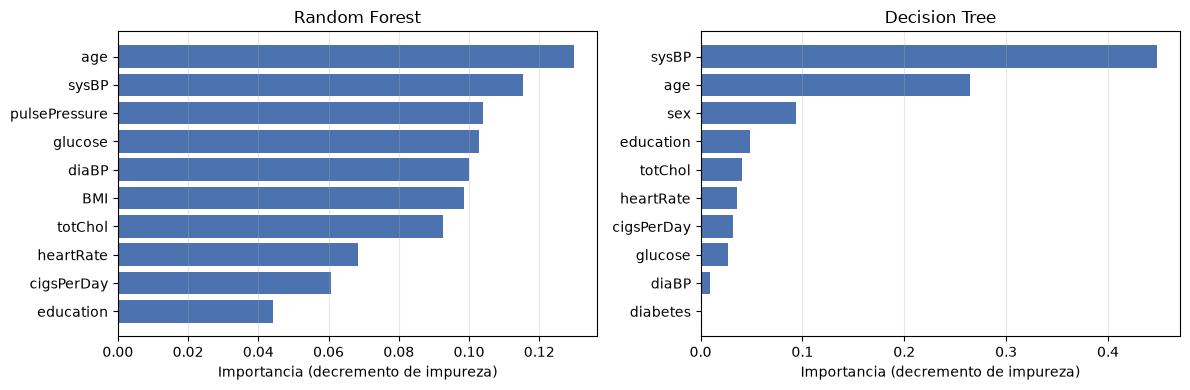

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
plot_importances(bosque.feature_importances_, list(X.columns), top_n=10, ax=axs[0],
                 title="Random Forest")
plot_importances(arbol.feature_importances_, list(X.columns), top_n=10, ax=axs[1],
                 title="Decision Tree")
plt.tight_layout()
plt.show()

<a id="6"></a>
## 6. Validación de las implementaciones contra scikit-learn

Antes de sacar conclusiones, se verifica que las implementaciones propias
reproducen a las de scikit-learn con la misma configuración. Es un *sanity
check*: si las métricas quedan cerca, el código está bien.

In [14]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

filas = []
for nombre, modelo in [
    ("DT propio (entropía + gain ratio)", DecisionTree(max_depth=6)),
    ("DT propio (entropía + gain)", DecisionTree(max_depth=6, split_metric="gain")),
    ("DT propio (gini)", DecisionTree(max_depth=6, criterion="gini")),
    ("DT sklearn (entropy)", DecisionTreeClassifier(max_depth=6, criterion="entropy", random_state=0)),
    ("DT sklearn (gini)", DecisionTreeClassifier(max_depth=6, criterion="gini", random_state=0)),
    ("RF propio", RandomForest(n_estimators=100, max_depth=10, criterion="entropy", n_jobs=-1, random_state=0)),
    ("RF sklearn", RandomForestClassifier(n_estimators=100, max_depth=10, random_state=0, n_jobs=-1)),
]:
    t0 = time.perf_counter()
    modelo.fit(X_tr, y_tr)
    t = time.perf_counter() - t0
    proba = modelo.predict_proba(X_te)[:, 1]
    r = E.evaluate_with_train_threshold(
        y_tr, modelo.predict_proba(X_tr)[:, 1], y_te, proba,
        pred_test=modelo.predict(X_te),
    )
    filas.append({
        "modelo": nombre,
        **{m: r[m] for m in E.METRICS},
        "tiempo (s)": round(t, 3),
    })

comparacion_sklearn = pd.DataFrame(filas)
comparacion_sklearn.to_csv("results/comparacion_sklearn.csv", index=False)
comparacion_sklearn

,modelo,accuracy,balanced_accuracy,precision,recall,f1,f1_opt,roc_auc,pr_auc,threshold_opt,tiempo (s)
0,DT propio (entropía + gain ratio),0.8476,0.5284,0.4583,0.0719,0.1243,0.3211,0.6038,0.2329,0.1921,0.0580
1,DT propio (entropía + gain),0.8378,0.5199,0.3125,0.0654,0.1081,0.2055,0.6414,0.2388,0.2459,0.1000
2,DT propio (gini),0.8387,0.5394,0.3778,0.1111,0.1717,0.3419,0.6616,0.2570,0.2405,0.0820
3,DT sklearn (entropy),0.8358,0.5161,0.2812,0.0588,0.0973,0.2149,0.6521,0.2353,0.3333,0.0150
4,DT sklearn (gini),0.8456,0.5434,0.4474,0.1111,0.1780,0.3462,0.6636,0.2767,0.2500,0.0070
5,RF propio,0.8496,0.5188,0.5000,0.0458,0.0838,0.3529,0.7028,0.3419,0.2388,1.2090
6,RF sklearn,0.8515,0.5254,0.5625,0.0588,0.1065,0.3425,0.7054,0.3309,0.2538,0.1540


<a id="7"></a>
## 7. Protocolo experimental

- **Validación cruzada estratificada 5-fold** (media ± desvío entre folds).
- **Hold-out 70/30** para matrices de confusión y curvas (un solo corte).
- **Métricas**: accuracy, balanced accuracy, precision, recall, F1,
  ROC-AUC y PR-AUC (average precision).
- **F1 óptimo**: umbral aprendido en train y aplicado al fold/test (con 15 %
  de positivos, el umbral 0,5 casi nunca predice la clase 1).

> Un clasificador trivial que diga siempre "no" acierta ≈ **84,9 %**. Por eso
> la accuracy sola no alcanza: se reportan balanced accuracy, recall y PR-AUC.

In [15]:
def mostrar(res):
    '''Resumen legible de un resultado de cross_validate.'''
    return pd.DataFrame({
        "métrica": E.METRICS,
        "media": [res[m] for m in E.METRICS],
        "desvío": [res[f"{m}_std"] for m in E.METRICS],
    }).round(4)

<a id="8"></a>
## 8. Barrido de hiperparámetros — Decision Tree

Se estudia cómo cambia el rendimiento con la profundidad, el mínimo de
muestras por hoja, el criterio de impureza y la poda.

14.7 s


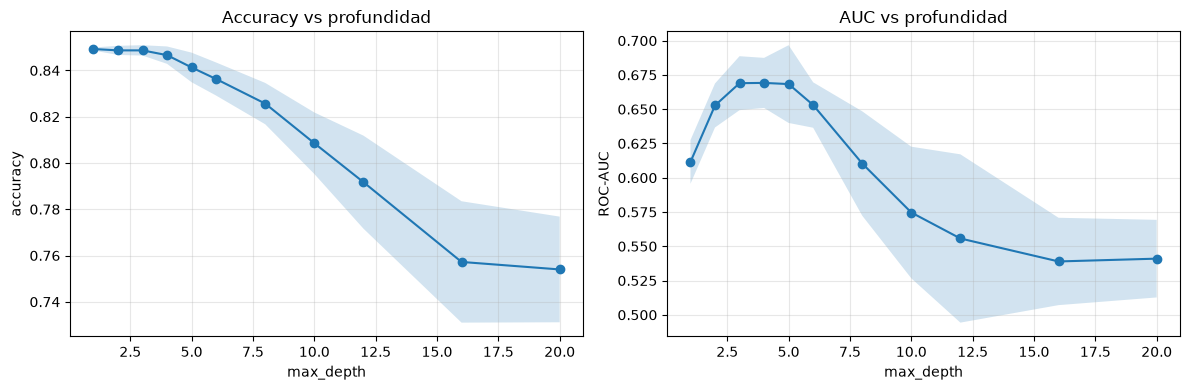

,max_depth,accuracy,balanced_accuracy,f1,f1_opt,roc_auc,leaves
0,1,0.8493,0.5000,0.0000,0.3204,0.6115,2.0000
1,2,0.8487,0.5117,0.0530,0.3367,0.6527,4.0000
2,3,0.8487,0.5101,0.0463,0.3352,0.6690,8.0000
3,4,0.8466,0.5218,0.0963,0.3277,0.6692,15.0000
4,5,0.8413,0.5195,0.0976,0.3459,0.6683,27.8000
5,6,0.8363,0.5310,0.1432,0.3323,0.6530,49.0000
6,8,0.8257,0.5360,0.1717,0.2272,0.6104,113.6000
7,10,0.8086,0.5380,0.1902,0.2146,0.5746,197.0000
8,12,0.7917,0.5394,0.2049,0.2042,0.5557,279.0000
9,16,0.7572,0.5327,0.2082,0.2119,0.5389,397.6000


In [16]:
t0 = time.perf_counter()
barrido_prof = E.sweep_with_preprocessing(
    E.make_dt, "max_depth", [1, 2, 3, 4, 5, 6, 8, 10, 12, 16, 20],
    df_raw, "TenYearCHD", PREP_FACTORY, n_splits=N_SPLITS,
    fixed={"criterion": "gini", "random_state": SEED}, verbose=False,
)
print(f"{time.perf_counter() - t0:.1f} s")
barrido_prof.to_csv("results/dt_barrido_profundidad.csv", index=False)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
plot_curve(barrido_prof["max_depth"], barrido_prof["accuracy"],
           barrido_prof["accuracy_std"], "max_depth", "accuracy",
           "Accuracy vs profundidad", ax=axs[0])
plot_curve(barrido_prof["max_depth"], barrido_prof["roc_auc"],
           barrido_prof["roc_auc_std"], "max_depth", "ROC-AUC",
           "AUC vs profundidad", ax=axs[1])
plt.tight_layout()
plt.show()
barrido_prof[["max_depth", "accuracy", "balanced_accuracy", "f1", "f1_opt",
              "roc_auc", "leaves"]].round(4)

In [17]:
barrido_hoja = E.sweep_with_preprocessing(
    E.make_dt, "min_samples_leaf", [1, 2, 5, 10, 20, 40, 80],
    df_raw, "TenYearCHD", PREP_FACTORY, n_splits=N_SPLITS,
    fixed={"criterion": "gini", "max_depth": 8, "random_state": SEED}, verbose=False,
)
barrido_hoja.to_csv("results/dt_barrido_min_hoja.csv", index=False)
barrido_hoja[["min_samples_leaf", "accuracy", "f1_opt", "roc_auc", "leaves"]].round(4)

,min_samples_leaf,accuracy,f1_opt,roc_auc,leaves
0,1,0.8257,0.2272,0.6104,113.6000
1,2,0.8248,0.2303,0.6091,111.6000
2,5,0.8292,0.2728,0.6218,94.6000
3,10,0.8336,0.2757,0.6336,79.2000
4,20,0.8413,0.2955,0.6369,65.0000
5,40,0.8457,0.3150,0.6590,45.4000
6,80,0.8437,0.3194,0.6632,26.4000


In [18]:
# Criterios de impureza y métrica de split (gain ratio de C4.5 vs gain puro)
filas = []
for criterion, split_metric, etiqueta in [
    ("entropy", "gain_ratio", "entropía + gain ratio"),
    ("entropy", "gain", "entropía + gain"),
    ("gini", None, "gini"),
]:
    r = E.cross_validate_with_preprocessing(
        df_raw, "TenYearCHD", PREP_FACTORY,
        lambda c=criterion, sm=split_metric: DecisionTree(
            max_depth=6, criterion=c, split_metric=sm, random_state=SEED
        ),
        n_splits=N_SPLITS, verbose=False,
    )
    r["criterion"] = criterion
    r["split_metric"] = split_metric
    filas.append(r)
    print(f"{etiqueta:24s} acc={r['accuracy']:.4f} auc={r['roc_auc']:.4f}")
barrido_criterio = pd.DataFrame(filas)
barrido_criterio.to_csv("results/dt_barrido_criterio.csv", index=False)
barrido_criterio[["criterion", "split_metric", "accuracy", "f1_opt",
                  "roc_auc", "leaves"]].round(4)

entropía + gain ratio    acc=0.8472 auc=0.5947


entropía + gain          acc=0.8372 auc=0.6542


gini                     acc=0.8363 auc=0.6530


,criterion,split_metric,accuracy,f1_opt,roc_auc,leaves
0,entropy,gain_ratio,0.8472,0.3020,0.5947,21.0000
1,entropy,gain,0.8372,0.3224,0.6542,53.0000
2,gini,NaN,0.8363,0.3323,0.6530,49.0000


In [19]:
# Poda: sin poda, pesimista (C4.5) y REP
filas = []
for etiqueta, poda in [("sin poda", False),
                       ("pesimista (C4.5)", "pessimistic"),
                       ("REP (20 % validación)", "rep")]:
    r = E.cross_validate_with_preprocessing(
        df_raw, "TenYearCHD", PREP_FACTORY,
        lambda: DecisionTree(max_depth=12, criterion="gini", random_state=SEED),
        n_splits=N_SPLITS, prune=poda, verbose=False,
    )
    r["poda"] = etiqueta
    filas.append(r)

barrido_poda = pd.DataFrame(filas)
barrido_poda.to_csv("results/dt_barrido_poda.csv", index=False)
barrido_poda[["poda", "accuracy", "f1_opt", "roc_auc", "leaves"]].round(4)

,poda,accuracy,f1_opt,roc_auc,leaves
0,sin poda,0.7917,0.2042,0.5557,279.0000
1,pesimista (C4.5),0.8142,0.2045,0.5774,163.8000
2,REP (20 % validación),0.8437,0.3439,0.6523,20.8000


In [20]:
# Efecto del balanceo de clases
filas = []
for etiqueta, cw in [("sin balanceo", None), ("balanced", "balanced")]:
    r = E.cross_validate_with_preprocessing(
        df_raw, "TenYearCHD", PREP_FACTORY,
        lambda cw=cw: DecisionTree(max_depth=6, criterion="gini", class_weight=cw, random_state=SEED),
        n_splits=N_SPLITS, verbose=False,
    )
    r["class_weight"] = etiqueta
    filas.append(r)
balanceo_dt = pd.DataFrame(filas)
balanceo_dt.to_csv("results/dt_class_weight.csv", index=False)
balanceo_dt[["class_weight", "accuracy", "balanced_accuracy", "precision",
             "recall", "f1"]].round(4)

,class_weight,accuracy,balanced_accuracy,precision,recall,f1
0,sin balanceo,0.8363,0.5310,0.3465,0.0940,0.1432
1,balanced,0.6383,0.6310,0.2375,0.6204,0.3423


<a id="9"></a>
## 9. Barrido de hiperparámetros — Random Forest

Cantidad de árboles (con curva OOB), atributos por split, profundidad y tipo
de voto.

126.2 s


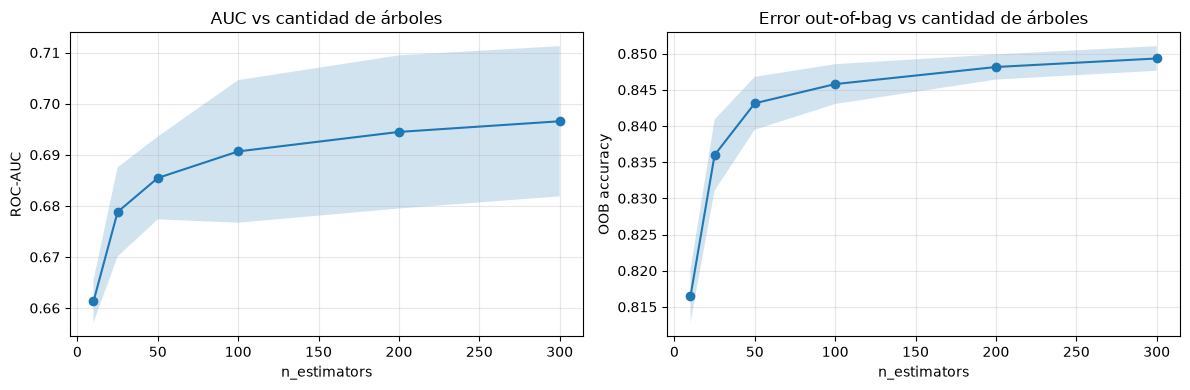

,n_estimators,accuracy,f1_opt,roc_auc,oob_accuracy,fit_time
0,10,0.8386,0.2714,0.6613,0.8165,0.3369
1,25,0.8460,0.2994,0.6788,0.8360,0.7167
2,50,0.8469,0.2941,0.6855,0.8431,1.4059
3,100,0.8490,0.3024,0.6907,0.8458,2.6437
4,200,0.8490,0.3227,0.6945,0.8482,5.2317
5,300,0.8493,0.3195,0.6966,0.8493,7.8642


In [21]:
t0 = time.perf_counter()
barrido_arboles = E.sweep_with_preprocessing(
    E.make_rf, "n_estimators", [10, 25, 50, 100, 200, 300],
    df_raw, "TenYearCHD", PREP_FACTORY, n_splits=N_SPLITS,
    fixed={"max_depth": 12, "criterion": "gini", "n_jobs": -1, "random_state": SEED},
    verbose=False,
)
print(f"{time.perf_counter() - t0:.1f} s")
barrido_arboles.to_csv("results/rf_barrido_arboles.csv", index=False)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
plot_curve(barrido_arboles["n_estimators"], barrido_arboles["roc_auc"],
           barrido_arboles["roc_auc_std"], "n_estimators", "ROC-AUC",
           "AUC vs cantidad de árboles", ax=axs[0])
plot_curve(barrido_arboles["n_estimators"], barrido_arboles["oob_accuracy"],
           barrido_arboles["oob_accuracy_std"], "n_estimators", "OOB accuracy",
           "Error out-of-bag vs cantidad de árboles", ax=axs[1])
plt.tight_layout()
plt.show()
barrido_arboles[["n_estimators", "accuracy", "f1_opt", "roc_auc",
                 "oob_accuracy", "fit_time"]].round(4)

In [22]:
barrido_mf = E.sweep_with_preprocessing(
    E.make_rf, "max_features", ["sqrt", "log2", 0.3, 0.6],
    df_raw, "TenYearCHD", PREP_FACTORY, n_splits=N_SPLITS,
    fixed={"n_estimators": 100, "max_depth": 12, "criterion": "gini", "n_jobs": -1, "random_state": SEED},
    verbose=False,
)
barrido_mf.to_csv("results/rf_barrido_max_features.csv", index=False)
barrido_mf[["max_features", "accuracy", "f1_opt", "roc_auc", "oob_accuracy"]].round(4)

,max_features,accuracy,f1_opt,roc_auc,oob_accuracy
0,sqrt,0.8490,0.3024,0.6907,0.8458
1,log2,0.8490,0.3024,0.6907,0.8458
2,0.3000,0.8490,0.3024,0.6907,0.8458
3,0.6000,0.8484,0.3159,0.6773,0.8469


In [23]:
barrido_prof_rf = E.sweep_with_preprocessing(
    E.make_rf, "max_depth", [3, 5, 8, 12, 20, None],
    df_raw, "TenYearCHD", PREP_FACTORY, n_splits=N_SPLITS,
    fixed={"n_estimators": 100, "max_features": "sqrt", "criterion": "gini",
           "n_jobs": -1, "random_state": SEED},
    verbose=False,
)
barrido_prof_rf.to_csv("results/rf_barrido_profundidad.csv", index=False)
barrido_prof_rf[["max_depth", "accuracy", "f1_opt", "roc_auc",
                 "oob_accuracy"]].round(4)

,max_depth,accuracy,f1_opt,roc_auc,oob_accuracy
0,3.0000,0.8499,0.3562,0.7081,0.8499
1,5.0000,0.8499,0.3362,0.7149,0.8499
2,8.0000,0.8513,0.3273,0.7066,0.8491
3,12.0000,0.8490,0.3024,0.6907,0.8458
4,20.0000,0.8540,0.0831,0.6850,0.8454
5,NaN,0.8537,0.1070,0.6840,0.8450


In [24]:
filas = []
for voto in ["soft", "hard"]:
    r = E.cross_validate_with_preprocessing(
        df_raw, "TenYearCHD", PREP_FACTORY,
        lambda voto=voto: RandomForest(n_estimators=100, max_depth=12,
                                       criterion="gini", voting=voto, n_jobs=-1, random_state=SEED),
        n_splits=N_SPLITS, verbose=False,
    )
    r["voting"] = voto
    filas.append(r)
votacion = pd.DataFrame(filas)
votacion.to_csv("results/rf_voting.csv", index=False)
votacion[["voting", "accuracy", "f1_opt", "roc_auc"]].round(4)

,voting,accuracy,f1_opt,roc_auc
0,soft,0.8490,0.3024,0.6907
1,hard,0.8487,0.3112,0.6818


<a id="10"></a>
## 10. Ablaciones de pre-procesamiento

Cada configuración se evalúa con el pre-procesamiento ajustado **dentro** de
cada fold (sin fuga de información). Se mide el impacto de la estrategia de
imputación, del winsorizado, de `is_smoking` y de `pulsePressure`.

MICE + winsor + is_smoking (base) acc=0.8478 auc=0.6969


mediana + winsor           acc=0.8496 auc=0.6989


KNN + winsor               acc=0.8496 auc=0.6929


MICE sin winsor            acc=0.8496 auc=0.6961


MICE sin is_smoking        acc=0.8513 auc=0.6909


MICE sin pulsePressure     acc=0.8525 auc=0.6968


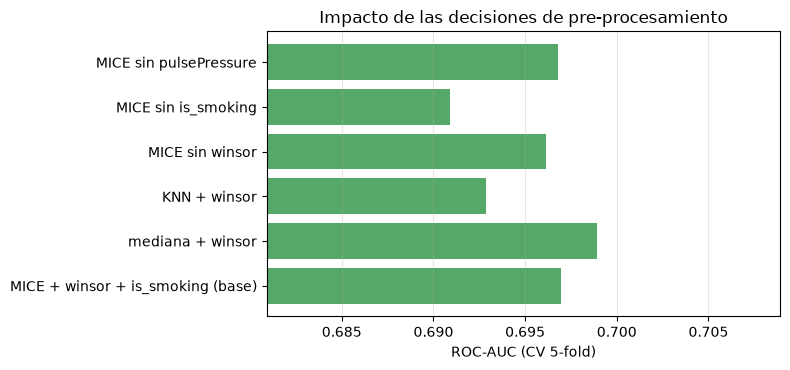

,configuracion,accuracy,f1_opt,roc_auc
0,MICE + winsor + is_smoking (base),0.8478,0.3299,0.6969
1,mediana + winsor,0.8496,0.3387,0.6989
2,KNN + winsor,0.8496,0.3100,0.6929
3,MICE sin winsor,0.8496,0.3330,0.6961
4,MICE sin is_smoking,0.8513,0.3303,0.6909
5,MICE sin pulsePressure,0.8525,0.3018,0.6968


In [25]:
configuraciones = [
    ("MICE + winsor + is_smoking (base)", dict(imputer="mice", clip_outliers=True)),
    ("mediana + winsor", dict(imputer="median", clip_outliers=True)),
    ("KNN + winsor", dict(imputer="knn", clip_outliers=True)),
    ("MICE sin winsor", dict(imputer="mice", clip_outliers=False)),
    ("MICE sin is_smoking", dict(imputer="mice", clip_outliers=True, drop_is_smoking=True)),
    ("MICE sin pulsePressure", dict(imputer="mice", clip_outliers=True, add_pulse_pressure=False)),
]

filas = []
for etiqueta, params in configuraciones:
    r = E.cross_validate_with_preprocessing(
        df_raw, "TenYearCHD",
        lambda p=params: preprocessing.Preprocessor(**p),
        lambda: RandomForest(n_estimators=80, max_depth=10, criterion="gini", n_jobs=-1, random_state=SEED),
        n_splits=N_SPLITS,
    )
    r["configuracion"] = etiqueta
    filas.append(r)
    print(f"{etiqueta:26s} acc={r['accuracy']:.4f} auc={r['roc_auc']:.4f}")

ablaciones = pd.DataFrame(filas)
ablaciones.to_csv("results/ablaciones_preprocesamiento.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(ablaciones["configuracion"], ablaciones["roc_auc"], color="#55A868")
ax.set_xlim(ablaciones["roc_auc"].min() - 0.01, ablaciones["roc_auc"].max() + 0.01)
ax.set_xlabel("ROC-AUC (CV 5-fold)")
ax.set_title("Impacto de las decisiones de pre-procesamiento")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()
ablaciones[["configuracion", "accuracy", "f1_opt", "roc_auc"]].round(4)

<a id="11"></a>
## 11. Comparación final DT vs RF

Se elige la mejor configuración de cada modelo **por ROC-AUC en validación
cruzada** (no por accuracy: con 15 % de positivos, la accuracy premia predecir
siempre la clase mayoritaria) y se comparan sobre el hold-out.

In [26]:
from itertools import product

# Las grillas también ajustan el preprocesamiento dentro de cada fold.
filas_grilla = []
for prof, hoja in product([4, 5, 6], [1, 5, 20, 40]):
    r = E.cross_validate_with_preprocessing(
        df_raw, "TenYearCHD", PREP_FACTORY,
        lambda p=prof, h=hoja: DecisionTree(
            max_depth=p, min_samples_leaf=h, criterion="gini", random_state=SEED
        ),
        n_splits=N_SPLITS, verbose=False,
    )
    filas_grilla.append({
        "max_depth": prof, "min_samples_leaf": hoja,
        "accuracy": r["accuracy"], "f1_opt": r["f1_opt"],
        "roc_auc": r["roc_auc"], "pr_auc": r["pr_auc"],
        "leaves": r["leaves"], "fit_time": r["fit_time"],
        "roc_auc_std": r["roc_auc_std"],
    })
grilla_dt = pd.DataFrame(filas_grilla)
grilla_dt.to_csv("results/grilla_dt.csv", index=False)
mejor_dt = grilla_dt.loc[grilla_dt["roc_auc"].idxmax()]

filas_grilla = []
for prof, mf in product([3, 5, 8], ["sqrt", 0.3, 0.6]):
    r = E.cross_validate_with_preprocessing(
        df_raw, "TenYearCHD", PREP_FACTORY,
        lambda p=prof, m=mf: RandomForest(
            n_estimators=100, max_depth=p, max_features=m,
            criterion="gini", n_jobs=-1, random_state=SEED,
        ),
        n_splits=N_SPLITS, verbose=False,
    )
    filas_grilla.append({
        "max_depth": prof, "max_features": str(mf),
        "accuracy": r["accuracy"], "f1_opt": r["f1_opt"],
        "roc_auc": r["roc_auc"], "pr_auc": r["pr_auc"],
        "oob_accuracy": r["oob_accuracy"], "fit_time": r["fit_time"],
        "roc_auc_std": r["roc_auc_std"],
    })
grilla_rf = pd.DataFrame(filas_grilla)
grilla_rf.to_csv("results/grilla_rf.csv", index=False)
mejor_rf = grilla_rf.loc[grilla_rf["roc_auc"].idxmax()]

mejor_arboles = int(barrido_arboles.loc[barrido_arboles["roc_auc"].idxmax(), "n_estimators"])
mejor_mf = mejor_rf["max_features"]
if mejor_mf not in ("sqrt", "log2"):
    mejor_mf = float(mejor_mf)
mejor_prof = int(mejor_dt["max_depth"])
mejor_hoja = int(mejor_dt["min_samples_leaf"])
mejor_prof_rf = int(mejor_rf["max_depth"])

print("Mejor DT :", dict(max_depth=mejor_prof, min_samples_leaf=mejor_hoja, criterion="gini"))
print("Mejor RF :", dict(n_estimators=mejor_arboles, max_depth=mejor_prof_rf,
                        max_features=mejor_mf, criterion="gini"))

config_dt = dict(max_depth=mejor_prof, min_samples_leaf=mejor_hoja,
                 criterion="gini", random_state=SEED)
config_rf = dict(n_estimators=mejor_arboles, max_depth=mejor_prof_rf,
                 max_features=mejor_mf, criterion="gini", n_jobs=-1,
                 random_state=SEED)

cv_dt = E.cross_validate_with_preprocessing(
    df_raw, "TenYearCHD", PREP_FACTORY,
    lambda: DecisionTree(**config_dt), n_splits=N_SPLITS,
)
cv_rf = E.cross_validate_with_preprocessing(
    df_raw, "TenYearCHD", PREP_FACTORY,
    lambda: RandomForest(**config_rf), n_splits=N_SPLITS,
)

tabla_cv = pd.DataFrame([
    {"modelo": "Decision Tree", **{m: cv_dt[m] for m in E.METRICS}, "tiempo (s)": cv_dt["fit_time"]},
    {"modelo": "Random Forest", **{m: cv_rf[m] for m in E.METRICS}, "tiempo (s)": cv_rf["fit_time"]},
]).set_index("modelo")

tabla_cv_csv = pd.DataFrame([
    {"modelo": "DT", **cv_dt},
    {"modelo": "RF", **cv_rf},
])
tabla_cv_csv.to_csv("results/comparacion_final_cv.csv", index=False)
tabla_cv.round(4)

Mejor DT : {'max_depth': 5, 'min_samples_leaf': 40, 'criterion': 'gini'}
Mejor RF : {'n_estimators': 300, 'max_depth': 5, 'max_features': 'sqrt', 'criterion': 'gini'}


,accuracy,balanced_accuracy,precision,recall,f1,f1_opt,roc_auc,pr_auc,threshold_opt,tiempo (s)
modelo,,,,,,,,,,
Decision Tree,0.8454,0.5211,0.4152,0.0568,0.0954,0.3493,0.6820,0.2664,0.2341,0.0518
Random Forest,0.8504,0.5063,0.5667,0.0137,0.0267,0.3252,0.7153,0.3294,0.2469,1.2919


In [27]:
# Hold-out 70/30: modelos finales
# El preprocesador ya fue ajustado únicamente sobre X_tr/y_tr en la celda 12.
modelos = {}
fit_times = {}
for nombre, factory in [
    ("Decision Tree", lambda: DecisionTree(**config_dt)),
    ("Random Forest", lambda: RandomForest(**config_rf)),
]:
    t0 = time.perf_counter()
    modelos[nombre] = factory().fit(X_tr, y_tr)
    fit_times[nombre] = time.perf_counter() - t0
probas = {n: m.predict_proba(X_te)[:, 1] for n, m in modelos.items()}
preds = {n: m.predict(X_te) for n, m in modelos.items()}

filas = []
filas_csv = []
for nombre in modelos:
    r = E.evaluate_with_train_threshold(
        y_tr, modelos[nombre].predict_proba(X_tr)[:, 1],
        y_te, probas[nombre], pred_test=preds[nombre],
    )
    cm = E.confusion(y_te, preds[nombre]).tolist()
    pred_opt = (probas[nombre] >= r["threshold_opt"]).astype(int)
    cm_opt = E.confusion(y_te, pred_opt).tolist()
    hojas = (modelos[nombre].get_n_leaves()
             if hasattr(modelos[nombre], "get_n_leaves")
             else np.mean([t.get_n_leaves() for t in modelos[nombre].estimators_]))
    filas.append({"modelo": nombre, **r, "hojas": hojas})
    filas_csv.append({"modelo": "DT" if nombre == "Decision Tree" else "RF",
                      **r, "tiempo (s)": fit_times[nombre],
                      "matriz_confusion": cm,
                      "matriz_confusion_opt": cm_opt})
tabla_holdout = pd.DataFrame(filas).set_index("modelo")
pd.DataFrame(filas_csv).to_csv("results/comparacion_final_holdout.csv", index=False)
np.save("results/final_probas.npy", {"y": y_te, "probas": {"DT": probas["Decision Tree"], "RF": probas["Random Forest"]}}, allow_pickle=True)
tabla_holdout.round(4)

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,threshold_opt,f1_opt,hojas
modelo,,,,,,,,,,
Decision Tree,0.8476,0.5446,0.4722,0.1111,0.1799,0.6728,0.2766,0.2165,0.3406,21.0000
Random Forest,0.8496,0.5027,0.5000,0.0065,0.0129,0.7186,0.3350,0.2415,0.3662,30.9033


In [28]:
print("F1 con umbral aprendido en train:")
for nombre in modelos:
    print(f"  {nombre:14s} umbral={tabla_holdout.loc[nombre, 'threshold_opt']:.3f}  "
          f"F1={tabla_holdout.loc[nombre, 'f1_opt']:.4f}")

F1 con umbral aprendido en train:
  Decision Tree  umbral=0.216  F1=0.3406
  Random Forest  umbral=0.242  F1=0.3662


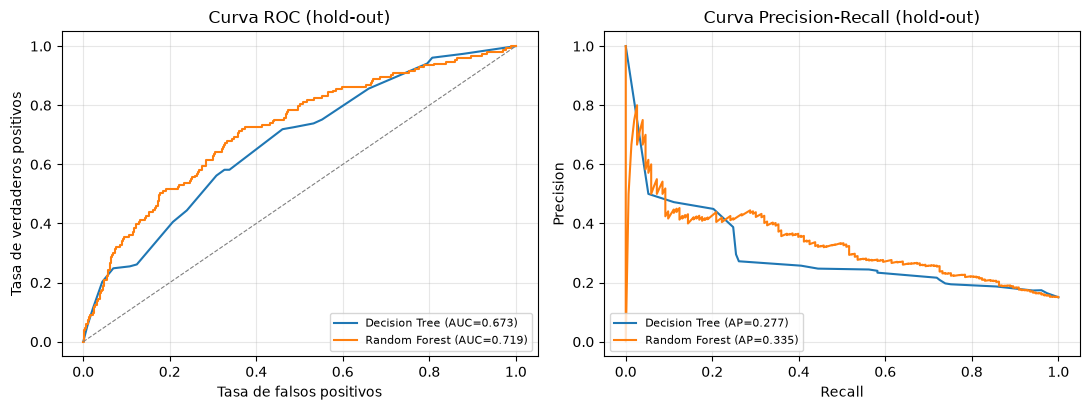

In [29]:
plot_roc_pr(y_te, probas, title_suffix=" (hold-out)")
plt.show()

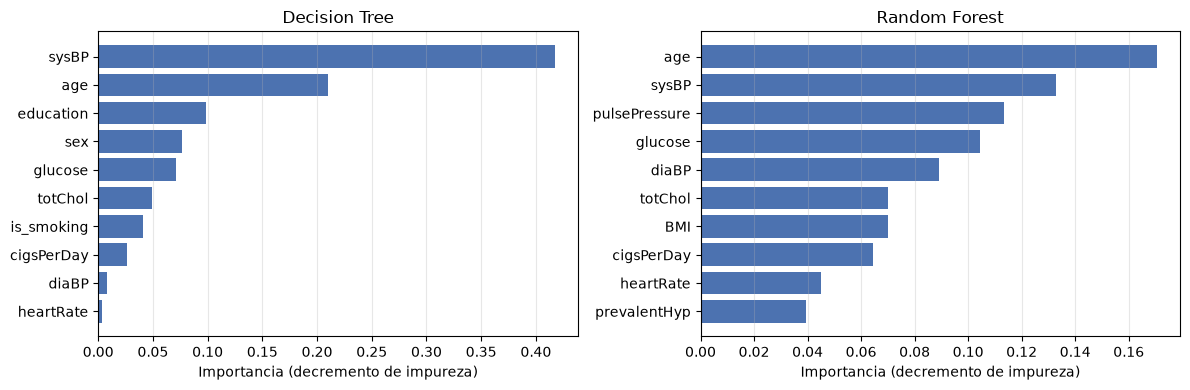

,atributo,DT,RF
0,age,0.2103,0.1706
10,sysBP,0.4173,0.1330
15,pulsePressure,0.0000,0.1133
14,glucose,0.0706,0.1045
11,diaBP,0.0077,0.0891
9,totChol,0.0495,0.0702
12,BMI,0.0000,0.0700
4,cigsPerDay,0.0263,0.0643
13,heartRate,0.0030,0.0451
7,prevalentHyp,0.0000,0.0396


In [30]:
# Importancias sobre el hold-out
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
plot_importances(modelos["Decision Tree"].feature_importances_, list(X.columns),
                 top_n=10, ax=axs[0], title="Decision Tree")
plot_importances(modelos["Random Forest"].feature_importances_, list(X.columns),
                 top_n=10, ax=axs[1], title="Random Forest")
plt.tight_layout()
plt.show()

importancias = pd.DataFrame({
    "atributo": list(X.columns),
    "DT": modelos["Decision Tree"].feature_importances_.round(4),
    "RF": modelos["Random Forest"].feature_importances_.round(4),
}).sort_values("RF", ascending=False)
importancias.to_csv("results/importancias.csv", index=False)
importancias

In [31]:
# Comparación estadística sobre las exactitudes por fold (Wilcoxon)
from sklearn.model_selection import StratifiedKFold

def exactitudes_por_fold(make, df_raw, n_splits=N_SPLITS):
    y_raw = df_raw["TenYearCHD"].to_numpy()
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    out = []
    for k, (tr, te) in enumerate(skf.split(np.zeros(len(y_raw)), y_raw), start=1):
        prep = preprocessing.Preprocessor()
        clean_tr = prep.fit_transform(df_raw.iloc[tr].reset_index(drop=True))
        clean_te = prep.transform(df_raw.iloc[te].reset_index(drop=True))
        X_fold_tr = clean_tr.drop(columns=["TenYearCHD"])
        y_fold_tr = clean_tr["TenYearCHD"].to_numpy()
        X_fold_te = clean_te.drop(columns=["TenYearCHD"])
        y_fold_te = clean_te["TenYearCHD"].to_numpy()
        m = make()
        m.fit(X_fold_tr, y_fold_tr)
        out.append(float((m.predict(X_fold_te) == y_fold_te).mean()))
    return np.array(out)

acc_dt = exactitudes_por_fold(lambda: DecisionTree(**config_dt), df_raw)
acc_rf = exactitudes_por_fold(lambda: RandomForest(**config_rf), df_raw)
print("DT por fold:", np.round(acc_dt, 4))
print("RF por fold:", np.round(acc_rf, 4))

try:
    from scipy.stats import wilcoxon
    stat, p = wilcoxon(acc_dt, acc_rf)
    print(f"Wilcoxon: estadístico={stat:.3f}, p={p:.4f}")
    print("Advertencia: los folds se solapan; este p-valor es descriptivo, no una prueba independiente.")
except Exception as e:
    print("scipy no disponible:", e)

DT por fold: [0.8437 0.8451 0.8407 0.851  0.8466]
RF por fold: [0.851  0.8496 0.8496 0.851  0.851 ]
Wilcoxon: estadístico=0.000, p=0.1250
Advertencia: los folds se solapan; este p-valor es descriptivo, no una prueba independiente.


<a id="12"></a>
## 12. Interfaz para correr pruebas

Dos formas de usar el TP:

1. **`run_experiment(...)`**: función programática. Devuelve la tabla de
   métricas y los modelos entrenados (sirve para automatizar o testear).
2. **Panel interactivo**: controles para cambiar la parametrización y ver los
   resultados sin tocar código.

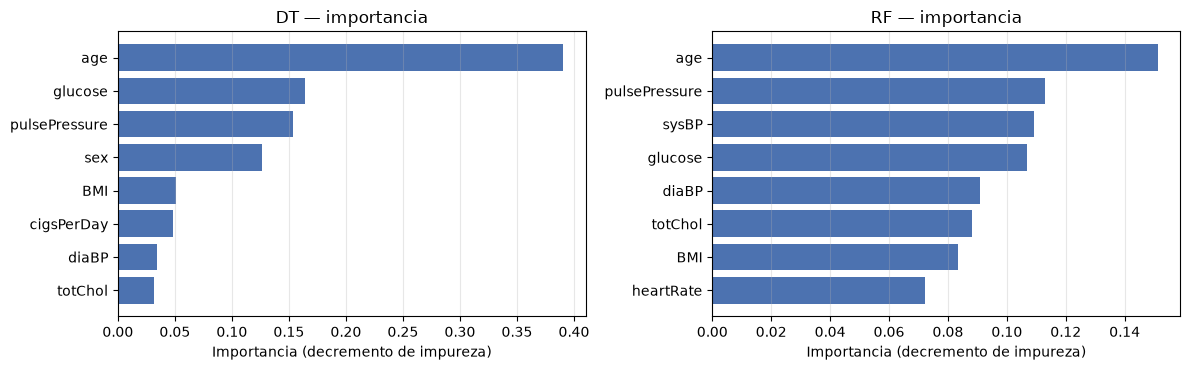

,accuracy,balanced_accuracy,precision,recall,f1,f1_opt,roc_auc,pr_auc,threshold_opt,tiempo (s)
modelo,,,,,,,,,,
Decision Tree,0.8478,0.5177,0.5111,0.0451,0.0765,0.3387,0.6763,0.2663,0.2216,0.0344
Random Forest,0.8513,0.5189,0.5752,0.0431,0.0799,0.3273,0.7066,0.3224,0.2685,1.2869


In [32]:
def run_experiment(
    dt_max_depth=4,
    dt_min_samples_leaf=20,
    dt_criterion="gini",
    dt_class_weight=None,
    rf_n_estimators=100,
    rf_max_depth=8,
    rf_max_features="sqrt",
    rf_voting="soft",
    rf_class_weight=None,
    n_splits=5,
    incluir_graficos=True,
):
    '''Entrena DT y RF con la parametrización dada y devuelve la comparación.

    La validación ajusta el preprocesamiento dentro de cada fold. Los modelos
    devueltos se reentrenan sobre todo el dataset limpio para inspección.
    '''
    make_dt = lambda: DecisionTree(
        max_depth=dt_max_depth,
        min_samples_leaf=dt_min_samples_leaf,
        criterion=dt_criterion,
        class_weight=dt_class_weight,
        random_state=SEED,
    )
    make_rf = lambda: RandomForest(
        n_estimators=rf_n_estimators,
        max_depth=rf_max_depth,
        max_features=rf_max_features,
        voting=rf_voting,
        criterion="gini",
        class_weight=rf_class_weight,
        n_jobs=-1,
        random_state=SEED,
    )

    cv = {
        "Decision Tree": E.cross_validate_with_preprocessing(
            df_raw, "TenYearCHD", PREP_FACTORY, make_dt, n_splits=n_splits
        ),
        "Random Forest": E.cross_validate_with_preprocessing(
            df_raw, "TenYearCHD", PREP_FACTORY, make_rf, n_splits=n_splits
        ),
    }
    tabla = pd.DataFrame([
        {"modelo": nombre, **{m: res[m] for m in E.METRICS},
         "tiempo (s)": res["fit_time"]}
        for nombre, res in cv.items()
    ]).set_index("modelo")

    modelos = {
        "Decision Tree": make_dt().fit(X, y),
        "Random Forest": make_rf().fit(X, y),
    }

    if incluir_graficos:
        fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
        plot_importances(modelos["Decision Tree"].feature_importances_, list(X.columns),
                         top_n=8, ax=axs[0], title="DT — importancia")
        plot_importances(modelos["Random Forest"].feature_importances_, list(X.columns),
                         top_n=8, ax=axs[1], title="RF — importancia")
        plt.tight_layout()
        plt.show()

    return tabla, modelos, cv


tabla_ejemplo, modelos_ejemplo, cv_ejemplo = run_experiment()
tabla_ejemplo.round(4)

In [33]:
try:
    import ipywidgets as widgets
    from IPython.display import clear_output
    HAY_WIDGETS = True
except ImportError:
    HAY_WIDGETS = False
    print("ipywidgets no disponible. Usar run_experiment(...) directamente.")

if HAY_WIDGETS:
    estilo = {"description_width": "170px"}
    ancho = widgets.Layout(width="420px")

    w_dt_prof = widgets.IntSlider(4, 1, 20, 1, description="DT profundidad:", style=estilo, layout=ancho)
    w_dt_hoja = widgets.IntSlider(20, 1, 80, 1, description="DT mín. por hoja:", style=estilo, layout=ancho)
    w_dt_crit = widgets.Dropdown(options=["gini", "entropy"], value="gini",
                                 description="DT criterio:", style=estilo, layout=ancho)
    w_dt_cw = widgets.Dropdown(options=[("sin balanceo", None), ("balanced", "balanced")],
                               value=None, description="DT class_weight:", style=estilo, layout=ancho)
    w_rf_arb = widgets.IntSlider(100, 10, 300, 10, description="RF árboles:", style=estilo, layout=ancho)
    w_rf_prof = widgets.IntSlider(8, 1, 20, 1, description="RF profundidad:", style=estilo, layout=ancho)
    w_rf_mf = widgets.Dropdown(options=["sqrt", "log2", 0.3, 0.6], value="sqrt",
                               description="RF max_features:", style=estilo, layout=ancho)
    w_rf_voto = widgets.Dropdown(options=["soft", "hard"], value="soft",
                                 description="RF voto:", style=estilo, layout=ancho)
    w_rf_cw = widgets.Dropdown(options=[("sin balanceo", None), ("balanced", "balanced")],
                               value=None, description="RF class_weight:", style=estilo, layout=ancho)
    w_cv = widgets.IntSlider(5, 3, 10, 1, description="Folds CV:", style=estilo, layout=ancho)

    boton = widgets.Button(description="Ejecutar prueba", button_style="success",
                           icon="play", layout=widgets.Layout(width="200px"))
    salida = widgets.Output()

    def _ejecutar(_):
        with salida:
            clear_output(wait=True)
            print("Entrenando...")
            t0 = time.perf_counter()
            tabla, modelos, _ = run_experiment(
                dt_max_depth=w_dt_prof.value,
                dt_min_samples_leaf=w_dt_hoja.value,
                dt_criterion=w_dt_crit.value,
                dt_class_weight=w_dt_cw.value,
                rf_n_estimators=w_rf_arb.value,
                rf_max_depth=w_rf_prof.value,
                rf_max_features=w_rf_mf.value,
                rf_voting=w_rf_voto.value,
                rf_class_weight=w_rf_cw.value,
                n_splits=w_cv.value,
                incluir_graficos=False,
            )
            print(f"Listo en {time.perf_counter() - t0:.1f} s\n")
            display(tabla.round(4))
            dt = modelos["Decision Tree"]
            rf = modelos["Random Forest"]
            print("Modelos reentrenados sobre todo el dataset:")
            print(f"  DT: {dt.get_n_leaves()} hojas, profundidad {dt.get_depth()}")
            print(f"  RF: {len(rf.estimators_)} árboles, OOB accuracy = {rf.oob_score_:.4f}")
            print("El análisis de umbral está en la sección 11.")

    boton.on_click(_ejecutar)
    display(widgets.VBox([
        widgets.HTML("<b>Decision Tree</b>"),
        w_dt_prof, w_dt_hoja, w_dt_crit, w_dt_cw,
        widgets.HTML("<b>Random Forest</b>"),
        w_rf_arb, w_rf_prof, w_rf_mf, w_rf_voto, w_rf_cw,
        widgets.HTML("<b>Validación</b>"),
        w_cv, boton, salida,
    ]))

<a id="13"></a>
## 13. Conclusiones

Se completan en el informe (`informe.md`). Los puntos principales:

1. **El dataset está desbalanceado** (15 % de positivos). La accuracy es
   engañosa: un modelo constante acierta 84,9 %. Hay que mirar balanced
   accuracy, recall, F1 y PR-AUC.
2. **Decision Tree** es rápido (≈0,1 s), interpretable y sirve como línea base,
   pero es inestable: pequeños cambios en los datos cambian el árbol. Sin poda
   sobreajusta (muchas hojas, accuracy de train alta y AUC de test baja).
3. **Random Forest** mejora el AUC de forma consistente (≈+2 puntos en CV y
   +6 en el hold-out) y estabiliza las predicciones, a costa de ~20× más tiempo
   de entrenamiento y de perder interpretabilidad directa (se compensa con
   importancias y OOB).
4. **El gain ratio de C4.5 no siempre es el mejor criterio**: en este dataset
   la entropía con *information gain* y Gini generalizan mejor. Es un hallazgo
   interesante para discutir: el gain ratio penaliza splits con mucha
   entropía de partición y puede elegir cortes que aíslan pocos casos.
5. **Pre-procesamiento**: winsorizar apenas mueve el AUC (los árboles son
   robustos a outliers); imputar con MICE, mediana o KNN da resultados
   equivalentes; `pulsePressure` aporta poco pero no molesta.
6. **Poda**: REP con poca validación es demasiado agresiva en datos
   desbalanceados (colapsa el árbol); la poda pesimista de C4.5 es un mejor
   compromiso entre tamaño y rendimiento.

In [34]:
# Exportar todo lo necesario para el informe
resumen = {
    "bootstrap_commit": COMMIT,
    "dataset": {
        "filas": int(df_raw.shape[0]),
        "columnas": int(df_raw.shape[1]),
        "nulos_celda": int(info["missing_total_cells"]),
        "filas_con_nulos": int(info["missing_rows_any"]),
        "duplicados": int(info["duplicates"]["exactos"]),
        "positivos": int((df_raw["TenYearCHD"] == 1).sum()),
        "pct_positivos": round(float((df_raw["TenYearCHD"] == 1).mean() * 100), 2),
        "imputados": int(sum(prep.report_["imputados"].values())),
        "winsorizados": int(sum(prep.report_["winsorizados"].values())),
    },
    "config_dt": config_dt,
    "config_rf": {k: (None if v is None else str(v)) for k, v in config_rf.items()},
    "cv_dt": cv_dt,
    "cv_rf": cv_rf,
    "holdout": tabla_holdout.to_dict(),
    "baseline_mayoritaria": round(float((y == 0).mean()), 4),
    "protocolo": {
        "seed": SEED,
        "cv_folds": N_SPLITS,
        "holdout_test_size": 0.30,
        "preprocessing": "fit only on each training fold/train split",
        "threshold": "learned on train and applied to validation/test",
        "pr_auc": "average_precision",
        "cv_role": "hyperparameter selection/stability; independent holdout for final comparison",
    },
    "umbral_optimo": {
        n: [float(tabla_holdout.loc[n, "threshold_opt"]),
            float(tabla_holdout.loc[n, "f1_opt"])]
        for n in modelos
    },
}
with open("results/resumen_notebook.json", "w", encoding="utf-8") as f:
    json.dump(resumen, f, indent=2, ensure_ascii=False, default=float)

with open("results/protocolo.json", "w", encoding="utf-8") as f:
    json.dump(resumen["protocolo"], f, indent=2, ensure_ascii=False)

print("Resumen guardado en results/resumen_notebook.json")
print("Tablas en results/*.csv")

Resumen guardado en results/resumen_notebook.json
Tablas en results/*.csv
